### Results / Summary

This cell documents the traffic scene object detection experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [11]:
%%writefile case5_merge_results.py

"""
case5_merge_results.py

Purpose:
  Consolidate scattered Ultralytics YOLO / RT-DETR experiment outputs for Case 5.

Usage examples:
  python case5_merge_results.py --manual-only --out ./case5_summary

Outputs:
  - case5_summary_results.csv
  - case5_summary_results.md
  - case5_map_summary.png
  - case5_runtime_summary.png

Notes:
  - Ultralytics writes per-epoch metrics into results.csv. This script chooses the row with the
    highest metrics/mAP50-95(B) as the best epoch when results.csv is available.
  - Manual summary values are taken from the final notebook/PDF logs and can be edited below.
"""

from __future__ import annotations

import argparse
from pathlib import Path
from typing import Dict, List, Optional

import pandas as pd
import matplotlib.pyplot as plt


# Manual fallback summary from the final run logs.
# Edit paths/notes if your local run folder names differ.
MANUAL_RESULTS: List[Dict] = [
    {
        "experiment": "baseline_yolo26n_scratch",
        "model": "YOLO26n.yaml",
        "main_change": "from-scratch baseline",
        "epochs_trained": 100,
        "imgsz": 640,
        "precision": 0.450,
        "recall": 0.381,
        "mAP50": 0.345,
        "mAP50_95": 0.209,
        "train_hours": 7.032,
        "environment": "Kaggle T4",
        "note": "Baseline YOLO26n trained from scratch without pretrained weights.",
    },
    {
        "experiment": "exp1_yolo26s_pretrained",
        "model": "YOLO26s.pt",
        "main_change": "larger YOLO26 + COCO pretrained + 800px + freeze",
        "epochs_trained": 100,
        "imgsz": 800,
        "precision": 0.512,
        "recall": 0.424,
        "mAP50": 0.4109,
        "mAP50_95": 0.2542,
        "train_hours": 4.736,
        "environment": "Kaggle T4",
        "note": "Improves over baseline; larger backbone and pretrained weights help.",
    },
    {
        "experiment": "exp2_yolo26n_hr_aug",
        "model": "YOLO26n.pt",
        "main_change": "COCO pretrained + 960px + Mosaic/MixUp/CopyPaste/HSV",
        "epochs_trained": 100,
        "imgsz": 960,
        "precision": 0.490,
        "recall": 0.427,
        "mAP50": 0.409,
        "mAP50_95": 0.2547,
        "train_hours": 9.901,
        "environment": "Kaggle T4",
        "note": "Best small-model result, but high resolution greatly increases training time.",
    },
    {
        "experiment": "exp3_yolo26m_adamw_aug",
        "model": "YOLO26m.pt",
        "main_change": "larger YOLO26m + AdamW + cosine + stronger augmentation",
        "epochs_trained": 130,
        "imgsz": 800,
        "precision": 0.565,
        "recall": 0.457,
        "mAP50": 0.463,
        "mAP50_95": 0.288,
        "train_hours": 6.262,
        "environment": "Google Colab A100",
        "note": "Best overall mAP. TTA augment was not actually supported and reverted to single-scale validation.",
    },
    {
        "experiment": "exp4_yolov11n_speed",
        "model": "YOLOv11n.pt",
        "main_change": "alternative YOLOv11 architecture; speed/efficiency baseline",
        "epochs_trained": 98,
        "imgsz": 800,
        "precision": 0.502,
        "recall": 0.413,
        "mAP50": 0.4003,
        "mAP50_95": 0.2406,
        "train_hours": 2.938,
        "environment": "Kaggle T4",
        "note": "Fastest training among completed detectors, but lower mAP than YOLO26s/YOLO26n-HR.",
    },
    {
        "experiment": "exp5_rtdetr_l",
        "model": "RT-DETR-L.pt",
        "main_change": "Transformer detector, 512px, frozen early layers",
        "epochs_trained": 94,
        "imgsz": 512,
        "precision": 0.520,
        "recall": 0.445,
        "mAP50": 0.423,
        "mAP50_95": 0.242,
        "train_hours": 43122.3 / 3600,
        "environment": "Kaggle T4; stopped by time limit",
        "note": "Kaggle force-stopped near epoch 95; result reported from available best checkpoint.",
    },
]


def normalize_colnames(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    return df


def get_col(df: pd.DataFrame, candidates: List[str]) -> Optional[str]:
    lower_map = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    for c in df.columns:
        lc = c.lower()
        if any(cand.lower() in lc for cand in candidates):
            return c
    return None


def parse_run_dir(run_dir: Path) -> Optional[Dict]:
    results_path = run_dir / "results.csv"
    if not results_path.exists():
        return None
    try:
        df = normalize_colnames(pd.read_csv(results_path))
    except Exception as exc:
        print(f"[WARN] Failed to read {results_path}: {exc}")
        return None

    map5095_col = get_col(df, ["metrics/mAP50-95(B)", "mAP50-95", "map50-95"])
    map50_col = get_col(df, ["metrics/mAP50(B)", "mAP50"])
    precision_col = get_col(df, ["metrics/precision(B)", "precision"])
    recall_col = get_col(df, ["metrics/recall(B)", "recall"])
    epoch_col = get_col(df, ["epoch"])

    if not map5095_col:
        print(f"[WARN] No mAP50-95 column in {results_path}. Columns: {list(df.columns)}")
        return None

    # Choose best epoch by mAP50-95.
    best_idx = df[map5095_col].astype(float).idxmax()
    row = df.loc[best_idx]

    return {
        "experiment": run_dir.name,
        "model": "unknown",
        "main_change": "parsed from run directory",
        "epochs_trained": int(row[epoch_col]) + 1 if epoch_col else len(df),
        "imgsz": None,
        "precision": float(row[precision_col]) if precision_col else None,
        "recall": float(row[recall_col]) if recall_col else None,
        "mAP50": float(row[map50_col]) if map50_col else None,
        "mAP50_95": float(row[map5095_col]),
        "train_hours": None,
        "environment": "parsed",
        "note": f"Best epoch chosen from {results_path}",
        "run_dir": str(run_dir),
    }


def scan_run_roots(roots: List[Path]) -> List[Dict]:
    rows: List[Dict] = []
    seen = set()
    for root in roots:
        if not root.exists():
            print(f"[WARN] Root not found: {root}")
            continue
        for results_csv in root.rglob("results.csv"):
            run_dir = results_csv.parent
            if run_dir in seen:
                continue
            seen.add(run_dir)
            parsed = parse_run_dir(run_dir)
            if parsed:
                rows.append(parsed)
    return rows


def build_summary(manual_only: bool, roots: List[Path]) -> pd.DataFrame:
    parsed_rows = [] if manual_only else scan_run_roots(roots)
    if parsed_rows:
        df = pd.DataFrame(parsed_rows)
    else:
        df = pd.DataFrame(MANUAL_RESULTS)
    df = df.sort_values("mAP50_95", ascending=False).reset_index(drop=True)
    df["rank"] = range(1, len(df) + 1)
    return df


def save_outputs(df: pd.DataFrame, out_dir: Path) -> None:
    out_dir.mkdir(parents=True, exist_ok=True)
    csv_path = out_dir / "case5_summary_results.csv"
    md_path = out_dir / "case5_summary_results.md"
    df.to_csv(csv_path, index=False)
    df.to_markdown(md_path, index=False)

    # mAP comparison chart
    plot_df = df.sort_values("mAP50_95", ascending=True)
    plt.figure(figsize=(10, 5.5))
    y = range(len(plot_df))
    plt.barh(y, plot_df["mAP50_95"], label="mAP50-95")
    plt.barh(y, plot_df["mAP50"], alpha=0.45, label="mAP50")
    plt.yticks(y, plot_df["experiment"])
    plt.xlabel("Validation mAP")
    plt.title("Case 5: Validation mAP Comparison")
    plt.legend()
    plt.grid(axis="x", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_dir / "case5_map_summary.png", dpi=220)
    plt.close()

    if "train_hours" in df.columns and df["train_hours"].notna().any():
        plot_df2 = df.dropna(subset=["train_hours"]).sort_values("train_hours", ascending=True)
        plt.figure(figsize=(9, 4.8))
        plt.barh(plot_df2["experiment"], plot_df2["train_hours"])
        plt.xlabel("Training time (hours, not strictly comparable across hardware)")
        plt.title("Approximate Training Time")
        plt.grid(axis="x", linestyle="--", alpha=0.3)
        plt.tight_layout()
        plt.savefig(out_dir / "case5_runtime_summary.png", dpi=220)
        plt.close()

    print(f"Saved: {csv_path}")
    print(f"Saved: {md_path}")
    print(f"Saved charts in: {out_dir}")


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--roots", nargs="*", default=["./runs/detect", "./runs", "/content/drive/MyDrive/YOLO_Experiments"],
                        help="Run roots to scan recursively for Ultralytics results.csv files.")
    parser.add_argument("--out", default="./case5_summary", help="Output directory.")
    parser.add_argument("--manual-only", action="store_true", help="Use embedded manual final metrics instead of scanning run directories.")
    args = parser.parse_args()

    roots = [Path(p) for p in args.roots]
    df = build_summary(args.manual_only, roots)
    save_outputs(df, Path(args.out))
    print(df[["rank", "experiment", "model", "mAP50", "mAP50_95", "train_hours"]].to_string(index=False))


if __name__ == "__main__":
    main()

Overwriting case5_merge_results.py


In [12]:
!python case5_merge_results.py --manual-only --out ./case5_summary

Saved: case5_summary/case5_summary_results.csv
Saved: case5_summary/case5_summary_results.md
Saved charts in: case5_summary
 rank               experiment        model  mAP50  mAP50_95  train_hours
    1   exp3_yolo26m_adamw_aug   YOLO26m.pt 0.4630    0.2880     6.262000
    2      exp2_yolo26n_hr_aug   YOLO26n.pt 0.4090    0.2547     9.901000
    3  exp1_yolo26s_pretrained   YOLO26s.pt 0.4109    0.2542     4.736000
    4            exp5_rtdetr_l RT-DETR-L.pt 0.4230    0.2420    11.978417
    5      exp4_yolov11n_speed  YOLOv11n.pt 0.4003    0.2406     2.938000
    6 baseline_yolo26n_scratch YOLO26n.yaml 0.3450    0.2090     7.032000


### Summary / Training

This cell documents the traffic scene object detection experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

| experiment | train_hours |
|------------|-------------|
| baseline_yolo26n_scratch | 7.032 (Kaggle T4) |
| exp1_yolo26s_pretrained | 4.736 (Kaggle T4) |
| exp2_yolo26n_hr_aug | 9.901 (Kaggle T4) |
| exp3_yolo26m_adamw_aug | 6.262 (Colab A100) |
| exp4_yolov11n_speed | 2.938 (Kaggle T4) |


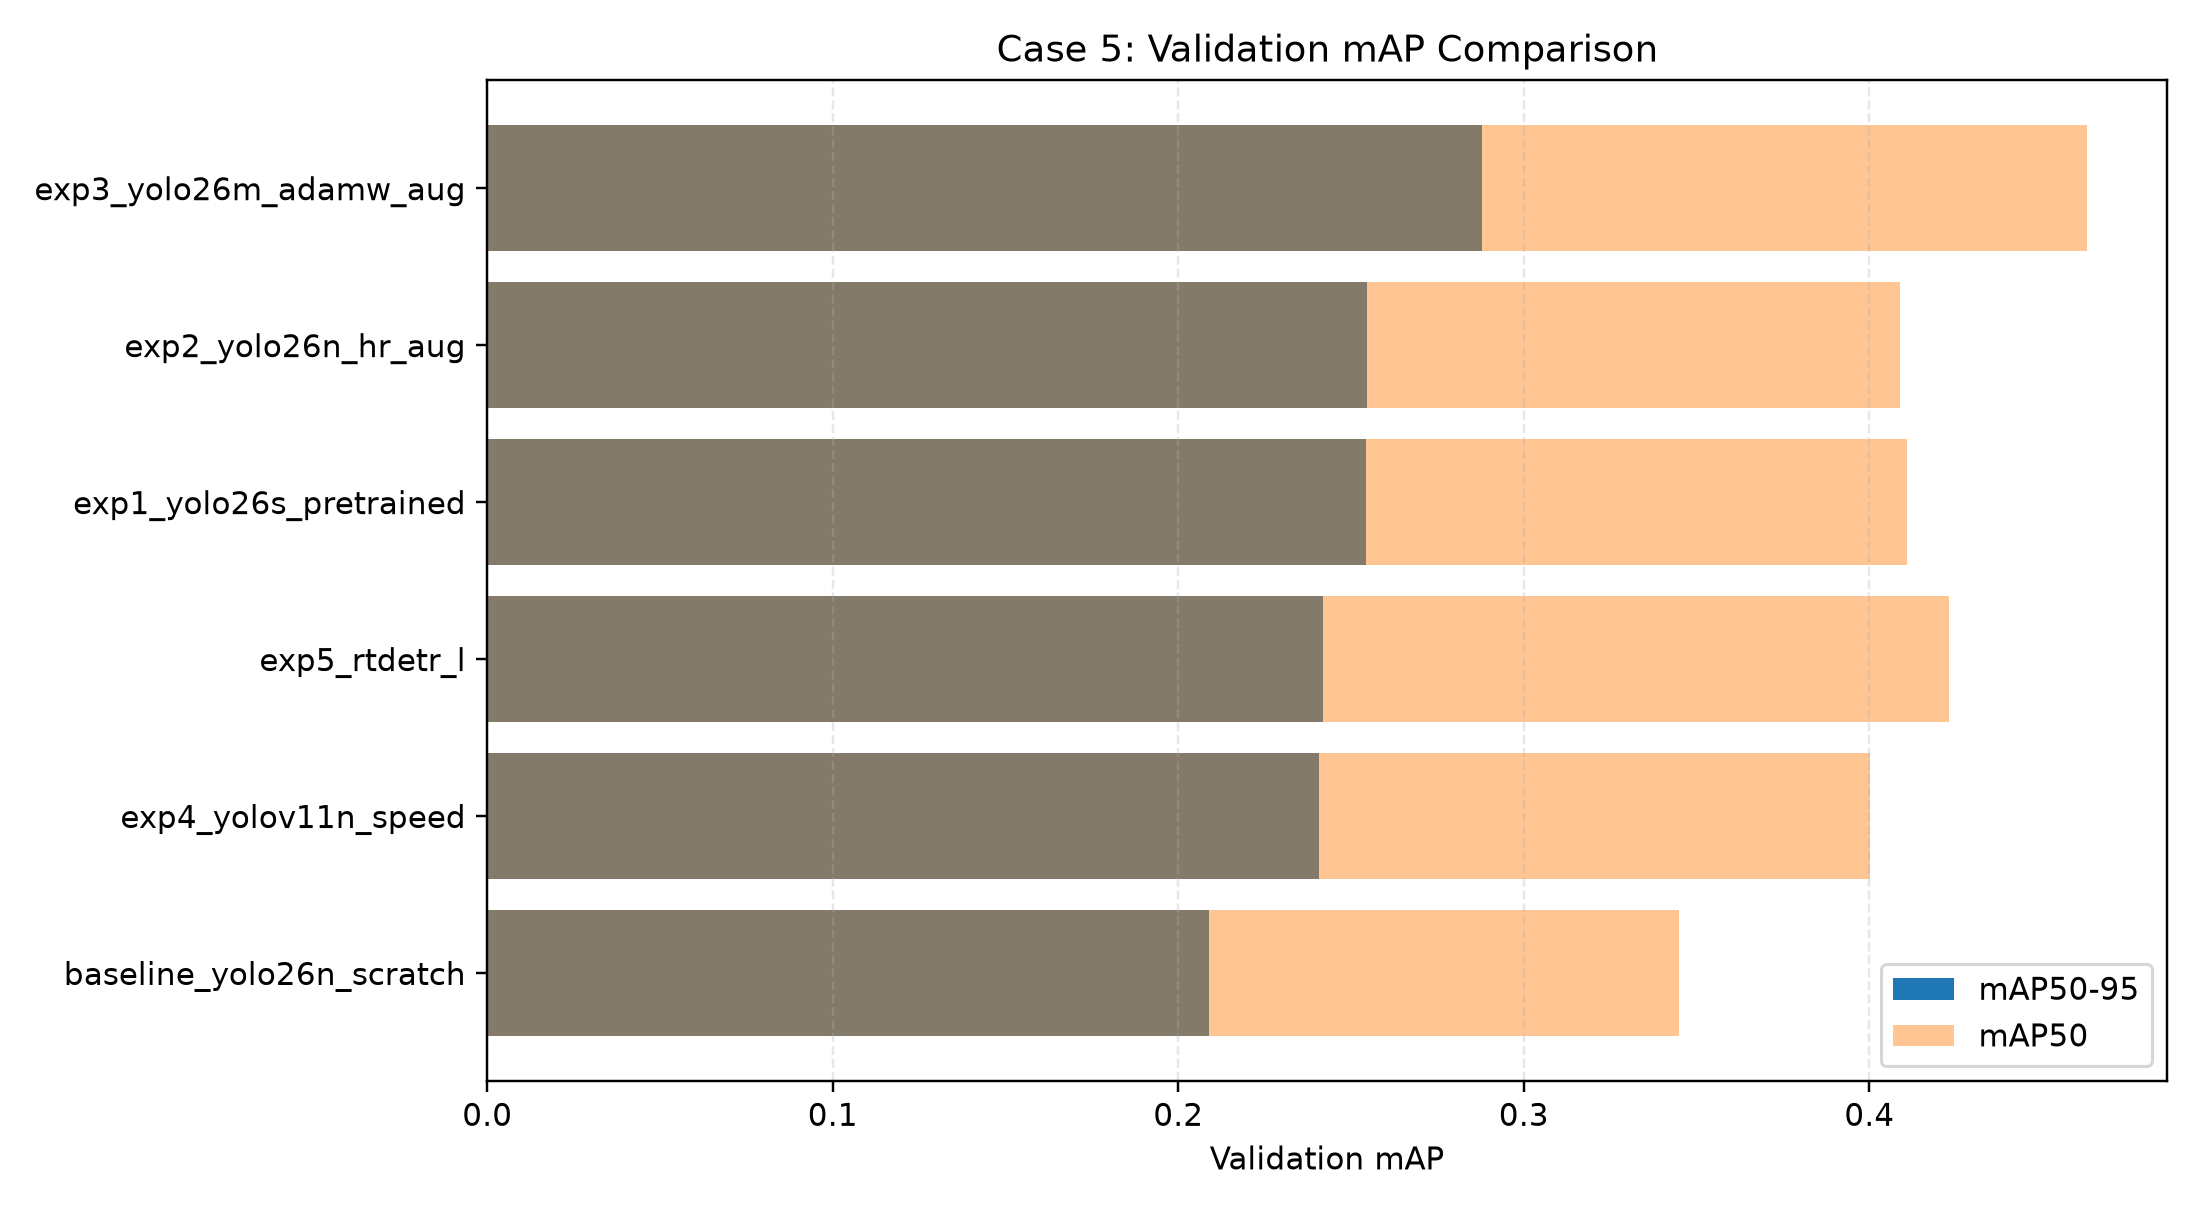

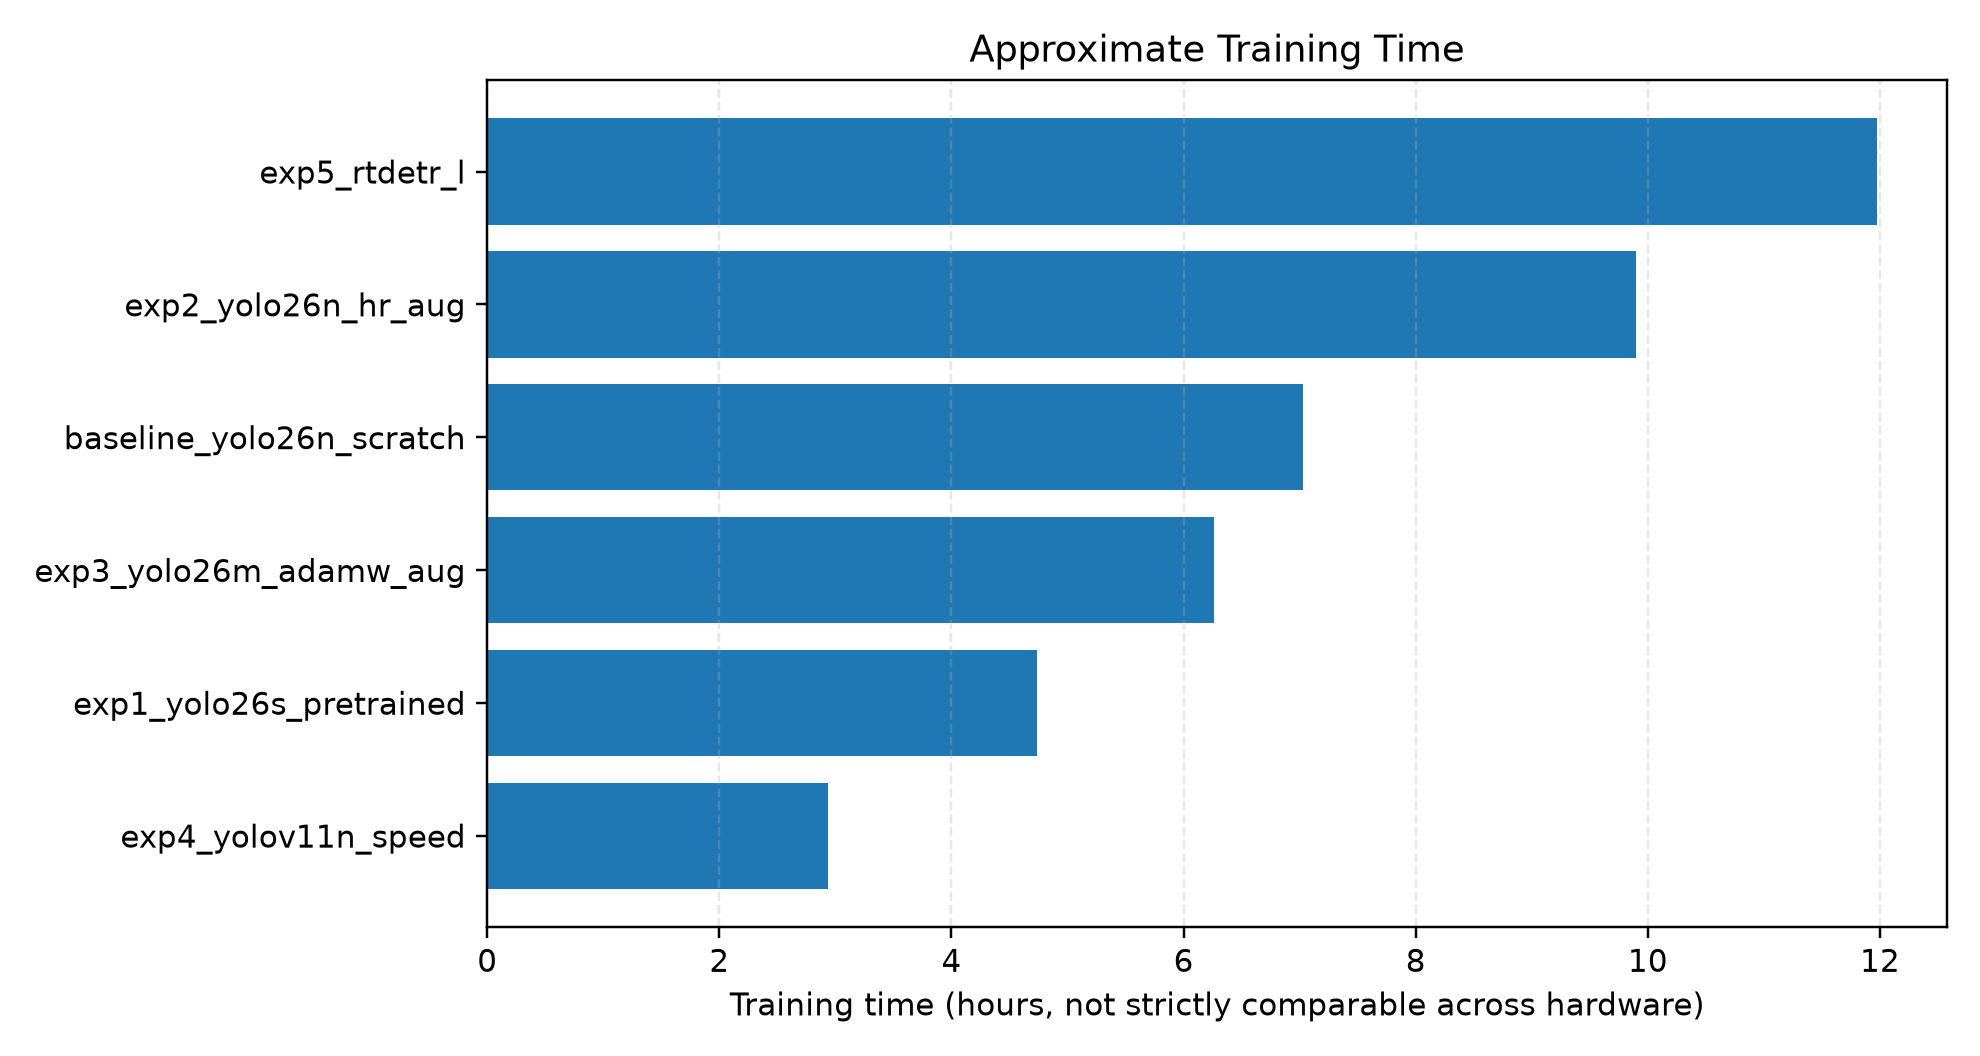

In [13]:
from IPython.display import Image, display

# 显示 mAP 对比图
display(Image(filename="./case5_summary/case5_map_summary.png"))

# Note on Training. Refer to the archived source for the detailed original comment.
display(Image(filename="./case5_summary/case5_runtime_summary.png"))